# Batch 3: PINC vs plain NN, 1-DOF pitch while hovering
**PINC** = a network that takes the state now and the input, and gives the state a short time later:

PINC(theta, q, M, dt) -> (theta, q) after dt

Chaining it (output becomes the next input) simulates a whole flight for any input M.

Trained with one loss, three parts:
1. **data**: from each measured state, one step of DT = 0.02 s must land on the next measured state
2. **start**: with dt = 0 the output must equal the input state
3. **physics**: at random made-up states, inputs and dt, the output must obey the hover equation
   theta' = q,  q' = -2 xi wn q - wn^2 (theta - th0) + mu M, with the constants the inverse PINN found (doublet notebook)

**Plain NN** = exactly the same network and training, with the physics part switched off.

Train: doublet_1 to doublet_5. Test: doublet_6 (unseen). 5 seeds per model.

## 0. Setup

In [1]:
import numpy as np, pandas as pd, torch, time, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
torch.set_num_threads(4)
D = '../data/1dof/'
FL = pd.read_csv(D + 'flights_1dof.csv').set_index('file')
TAU = 0.02                     # delay command -> motors [s]
DT = 0.02                      # one PINC step [s] (5 samples at 250 Hz)
TRAIN = [f'doublet_{i}.csv' for i in range(1, 6)]
TEST = 'doublet_6.csv'
SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 20000
# hover constants from the doublet notebook (results/batch1_2_doublet_constants.csv)
c = pd.read_csv('../results/batch1_2_doublet_constants.csv', index_col=0)
P_PINN = dict(wn=float(c.loc['wn [rad/s]', 'Inverse PINN (mean of 5)']), xi=float(c.loc['xi [-]', 'Inverse PINN (mean of 5)']),
              mu=float(c.loc['mu [rad/s^2]', 'Inverse PINN (mean of 5)']), th0=-0.1506)
P_SIM = dict(wn=float(c.loc['wn [rad/s]', 'Sim fit (5 flights)']), xi=float(c.loc['xi [-]', 'Sim fit (5 flights)']),
             mu=float(c.loc['mu [rad/s^2]', 'Sim fit (5 flights)']), th0=-0.1665)
print('PINC physics uses', {k: round(v, 3) for k, v in P_PINN.items()})

PINC physics uses {'wn': 3.843, 'xi': 0.105, 'mu': 159.925, 'th0': -0.151}


## 1. Data: each flight on a 0.02 s grid; M = delayed motor command averaged over the step

In [2]:
def load(name):
    r = FL.loc[name]; df = pd.read_csv(D + name)
    after = df[df.t > r.inj_start_s + 0.7]
    end = after.t[after.M.abs() > 0.12].iloc[0] - 0.05            # just before the motor kick-back
    f = df[(df.t >= r.inj_start_s - 0.1 - TAU) & (df.t < end)].reset_index(drop=True)
    f['t'] = f.t - f.t[0] - TAU                                    # t = 0 at the start; keep 0.02 s before it for the delay
    return f

def steps(f):
    t = np.arange(0, f.t.iloc[-1] - DT, DT)
    th = np.interp(t, f.t, f.theta); q = np.interp(t, f.t, f.q)
    M = np.array([np.mean(np.interp(np.linspace(ti, ti + DT, 6)[:-1] - TAU, f.t, f.M)) for ti in t])
    return t, th, q, M

flights = {n: load(n) for n in TRAIN + [TEST]}
grid = {n: steps(f) for n, f in flights.items()}
print('training pairs:', sum(len(g[0]) - 1 for n, g in grid.items() if n in TRAIN), '| test steps:', len(grid[TEST][0]))

training pairs: 357 | test steps: 73


## 2. Physics, written once

In [3]:
def accel(theta, q, M, p):
    return -2 * p['xi'] * p['wn'] * q - p['wn']**2 * (theta - p['th0']) + p['mu'] * M

def euler_like_ivp(p):
    # equation model as a step function: exact ODE solve over one DT with M held constant
    def step(th, q, M):
        y = solve_ivp(lambda t, z: [z[1], accel(z[0], z[1], M, p)], (0, DT), [th, q], max_step=DT / 5).y[:, -1]
        return y[0], y[1]
    return step

def vaf(y, yhat):
    return max(1 - np.var(y - yhat) / np.var(y), 0) * 100

## 3. The network and the PINC step

In [4]:
def mlp(n_in, n_out, width=32, depth=3):
    layers, n = [], n_in
    for _ in range(depth):
        layers += [torch.nn.Linear(n, width), torch.nn.Tanh()]; n = width
    return torch.nn.Sequential(*layers, torch.nn.Linear(n, n_out))

col = lambda x: torch.tensor(np.asarray(x), dtype=torch.float32).reshape(-1, 1)
S = dict(th=0.3, q=4.0, M=0.06)          # normalisation scales (inputs and outputs about -1..1)

def pinc_model(net):
    def step(th, q, M, dt):              # all torch columns; returns (theta, q) after dt
        x = torch.cat([th / S['th'], q / S['q'], M / S['M'], dt / DT], 1)
        o = net(x)
        return S['th'] * o[:, :1], S['q'] * o[:, 1:2]
    return step

## 4. Training function (PINC when w_phys = 1, plain NN when w_phys = 0)

In [5]:
def train_pinc(names, seed=0, epochs=EPOCHS, lr=1e-3, w_phys=1.0, n_col=2000, p=P_PINN):
    # data
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    G = [grid[n] for n in names]
    th0 = col(np.concatenate([g[1][:-1] for g in G])); q0 = col(np.concatenate([g[2][:-1] for g in G]))
    th1 = col(np.concatenate([g[1][1:] for g in G])); q1 = col(np.concatenate([g[2][1:] for g in G]))
    M0 = col(np.concatenate([g[3][:-1] for g in G]))
    # network
    net = mlp(4, 2); step = pinc_model(net)
    # optimizer
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    # loop
    hist = []
    for e in range(epochs):
        a, b = step(th0, q0, M0, torch.full_like(th0, DT))                    # one step of DT
        data = (((a - th1) / S['th'])**2).mean() + (((b - q1) / S['q'])**2).mean()
        a, b = step(th0, q0, M0, torch.zeros_like(th0))                       # dt = 0 -> same state
        start = (((a - th0) / S['th'])**2).mean() + (((b - q0) / S['q'])**2).mean()
        physics = torch.tensor(0.0)
        if w_phys > 0:
            zt = col(rng.uniform(-0.35, 0.35, n_col)); zq = col(rng.uniform(-4, 4, n_col))
            zM = col(rng.uniform(-0.06, 0.06, n_col)); dt = col(rng.uniform(0, DT, n_col)).requires_grad_(True)
            a, b = step(zt, zq, zM, dt)
            da = torch.autograd.grad(a, dt, torch.ones_like(a), create_graph=True)[0]    # d theta / d dt
            db = torch.autograd.grad(b, dt, torch.ones_like(b), create_graph=True)[0]    # d q / d dt
            physics = (((da - b) / S['q'])**2).mean() + (((db - accel(a, b, zM, p)) / (S['q'] / DT))**2).mean()
            a, b = step(zt, zq, zM, torch.zeros_like(zt))
            start = start + (((a - zt) / S['th'])**2).mean() + (((b - zq) / S['q'])**2).mean()
        loss = data + start + w_phys * physics
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if e % 1000 == 0 or e == epochs - 1:
            hist.append((e, data.item(), start.item(), physics.item()))
    return dict(net=net, step=step, history=pd.DataFrame(hist, columns=['epoch', 'data', 'start', 'physics']))

## 5. Runners: whole-flight rollout and one-step-ahead

In [6]:
def run_open(step_fn, th_start, q_start, M_list, is_torch=True):
    # chain the model: each output is the next input
    th, q = th_start, q_start; out = [th]
    for M in M_list[:-1]:
        if is_torch:
            with torch.no_grad():
                a, b = step_fn(col([th]), col([q]), col([M]), col([DT])); th, q = a.item(), b.item()
        else:
            th, q = step_fn(th, q, M)
        out.append(th)
    return np.array(out)

def run_one_step(step_fn, g, is_torch=True):
    t, th, q, M = g; out = [th[0]]
    for k in range(len(t) - 1):
        if is_torch:
            with torch.no_grad(): a, _ = step_fn(col([th[k]]), col([q[k]]), col([M[k]]), col([DT])); out.append(a.item())
        else:
            out.append(step_fn(th[k], q[k], M[k])[0])
    return np.array(out)

## 6. Train: 5 seeds x (PINC, plain NN)

In [7]:
runs = {'PINC': [], 'plain NN': []}
for s in SEEDS:
    for label, wp in [('PINC', 1.0), ('plain NN', 0.0)]:
        t0 = time.time(); r = train_pinc(TRAIN, seed=s, w_phys=wp); r['time'] = time.time() - t0
        runs[label].append(r); print(label, 'seed', s, f"{r['time']:.0f} s", r['history'].iloc[-1][['data', 'start', 'physics']].round(7).to_dict())

PINC seed 0 104 s {'data': 3.38e-05, 'start': 1.6e-06, 'physics': 4e-06}


plain NN seed 0 31 s {'data': 3.01e-05, 'start': 4e-07, 'physics': 0.0}


PINC seed 1 106 s {'data': 3.43e-05, 'start': 2e-06, 'physics': 3.5e-06}


plain NN seed 1 30 s {'data': 3.04e-05, 'start': 5e-07, 'physics': 0.0}


PINC seed 2 103 s {'data': 3.4e-05, 'start': 2.2e-06, 'physics': 4.9e-06}


plain NN seed 2 30 s {'data': 3.08e-05, 'start': 4e-07, 'physics': 0.0}


PINC seed 3 102 s {'data': 3.43e-05, 'start': 2.6e-06, 'physics': 4.4e-06}


plain NN seed 3 29 s {'data': 3.05e-05, 'start': 5e-07, 'physics': 0.0}


PINC seed 4 98 s {'data': 3.43e-05, 'start': 3e-06, 'physics': 7.2e-06}


plain NN seed 4 29 s {'data': 3.07e-05, 'start': 6e-07, 'physics': 0.0}


## 7. Test on doublet_6 (unseen): one step and rollout, error vs horizon

In [8]:
g = grid[TEST]; t, th, q, M = g
HOR = [0.25, 0.5, 1.0, 1.4]                              # seconds after the start
idx = [int(round(h / DT)) for h in HOR]
def score(pred_roll, pred_one):
    e = np.degrees(np.abs(pred_roll - th))
    return [vaf(th, pred_roll), np.degrees(np.sqrt(np.mean((pred_one - th)**2)))] + [e[i] for i in idx]
cols = ['rollout VAF [%]', 'one-step RMSE [deg]'] + [f'|error| at {h} s [deg]' for h in HOR]
rows = {}
for label, p in [('Equation, sim-fit constants', P_SIM), ('Equation, inverse-PINN constants', P_PINN)]:
    st = euler_like_ivp(p)
    rows[label] = score(run_open(st, th[0], q[0], M, False), run_one_step(st, g, False))
preds = {}
for label, rs in runs.items():
    S_ = np.array([score(run_open(r['step'], th[0], q[0], M), run_one_step(r['step'], g)) for r in rs])
    preds[label] = [run_open(r['step'], th[0], q[0], M) for r in rs]
    rows[label + ' (mean of 5)'] = S_.mean(0); rows[label + ' (std)'] = S_.std(0)
table = pd.DataFrame(rows, index=cols).T.round(3)
table.to_csv('../results/batch3_pinc_vs_plain_nn.csv')
table

,rollout VAF [%],one-step RMSE [deg],|error| at 0.25 s [deg],|error| at 0.5 s [deg],|error| at 1.0 s [deg],|error| at 1.4 s [deg]
"Equation, sim-fit constants",98.873,0.014,0.306,1.969,0.073,2.890
"Equation, inverse-PINN constants",99.095,0.015,0.136,0.038,0.262,2.746
PINC (mean of 5),99.063,0.015,0.321,1.088,0.863,3.142
PINC (std),0.075,0.001,0.029,0.149,0.083,0.165
plain NN (mean of 5),98.983,0.016,0.680,1.506,0.516,1.122
plain NN (std),0.082,0.000,0.042,0.043,0.116,0.138


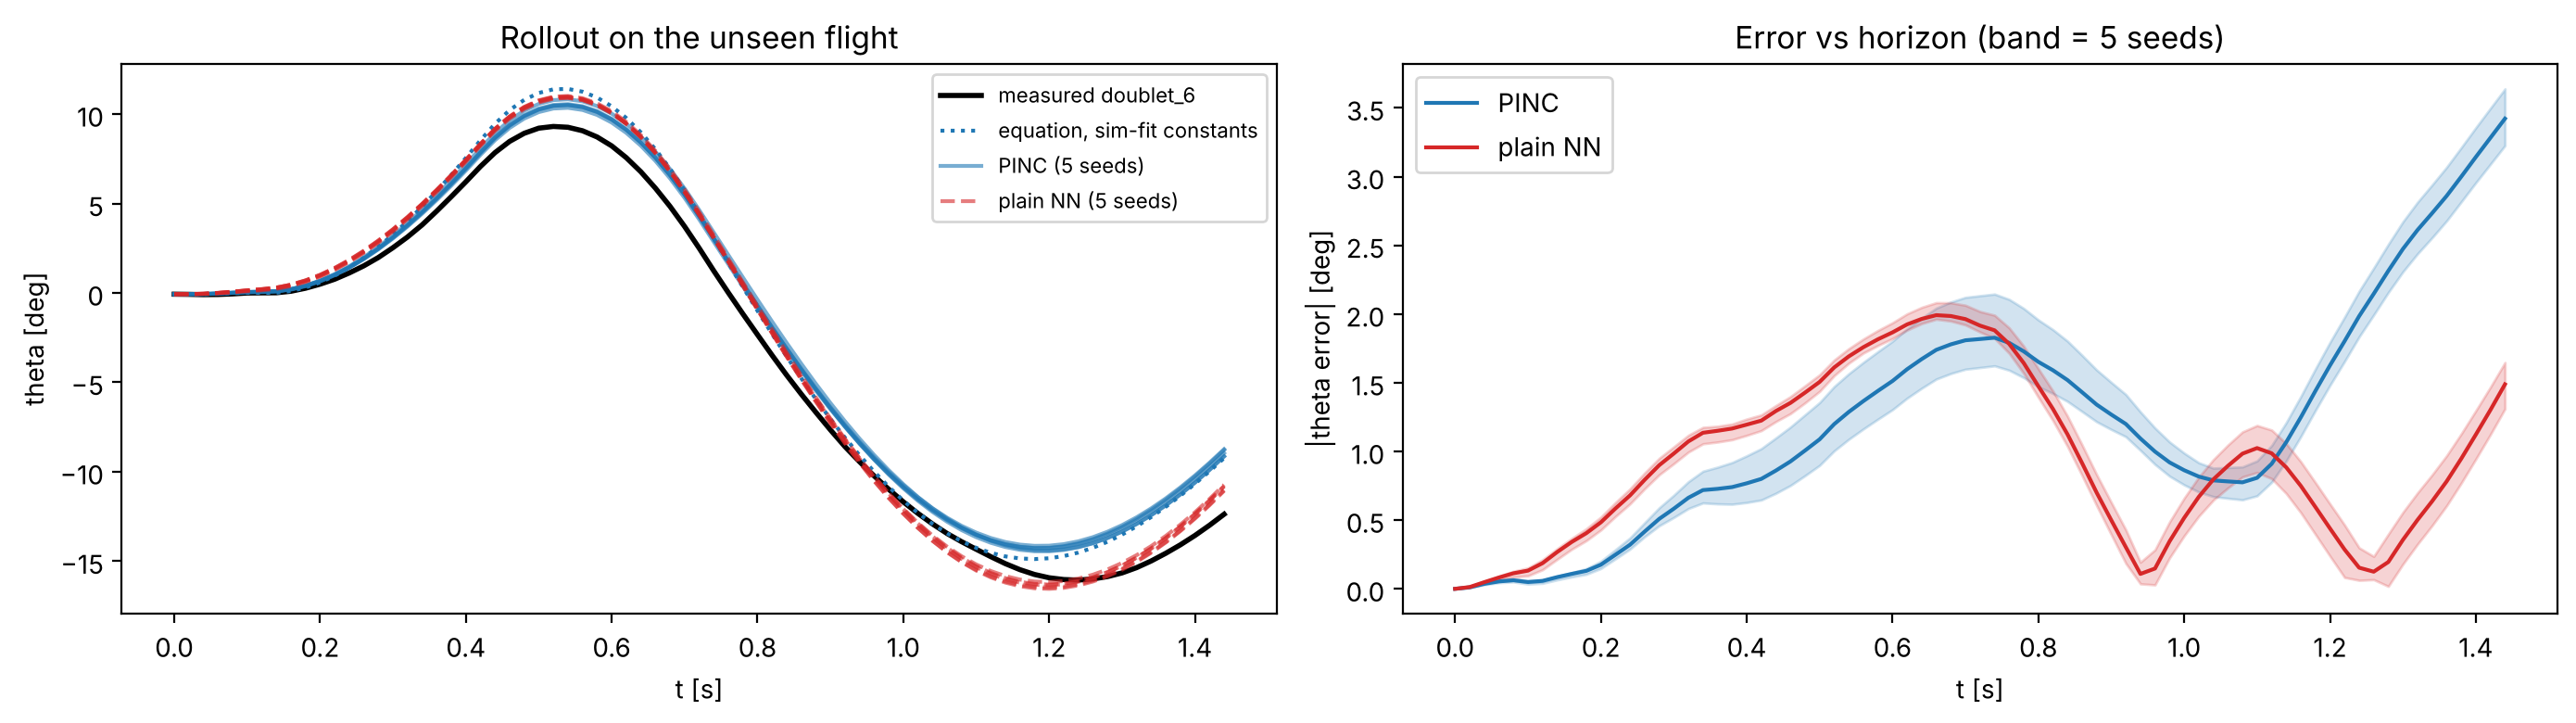

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(t, np.degrees(th), 'k', lw=2, label='measured doublet_6')
ax[0].plot(t, np.degrees(run_open(euler_like_ivp(P_SIM), th[0], q[0], M, False)), ':', label='equation, sim-fit constants')
for label, ls in [('PINC', '-'), ('plain NN', '--')]:
    for i, y in enumerate(preds[label]):
        ax[0].plot(t, np.degrees(y), ls, color='C0' if label == 'PINC' else 'C3', alpha=0.6, label=label + ' (5 seeds)' if i == 0 else None)
ax[0].set(xlabel='t [s]', ylabel='theta [deg]', title='Rollout on the unseen flight'); ax[0].legend(fontsize=8)
for label, color in [('PINC', 'C0'), ('plain NN', 'C3')]:
    E = np.array([np.degrees(np.abs(y - th)) for y in preds[label]])
    ax[1].plot(t, E.mean(0), color=color, label=label); ax[1].fill_between(t, E.min(0), E.max(0), color=color, alpha=0.2)
ax[1].set(xlabel='t [s]', ylabel='|theta error| [deg]', title='Error vs horizon (band = 5 seeds)'); ax[1].legend()
plt.tight_layout(); plt.savefig('../figures/batch3_pinc_vs_plain_nn.png', dpi=120, bbox_inches='tight'); plt.show()

## 8. New input never seen in training
The real test of a model for control: give it an input it has not seen. Here: the doublet_6 input made **1.5 times bigger** and a **long hold** (constant push for 1 s). There is no measured flight for these, so the reference is the equation with the sim-fit constants (the best model on doublet_6, VAF 98.8 %).

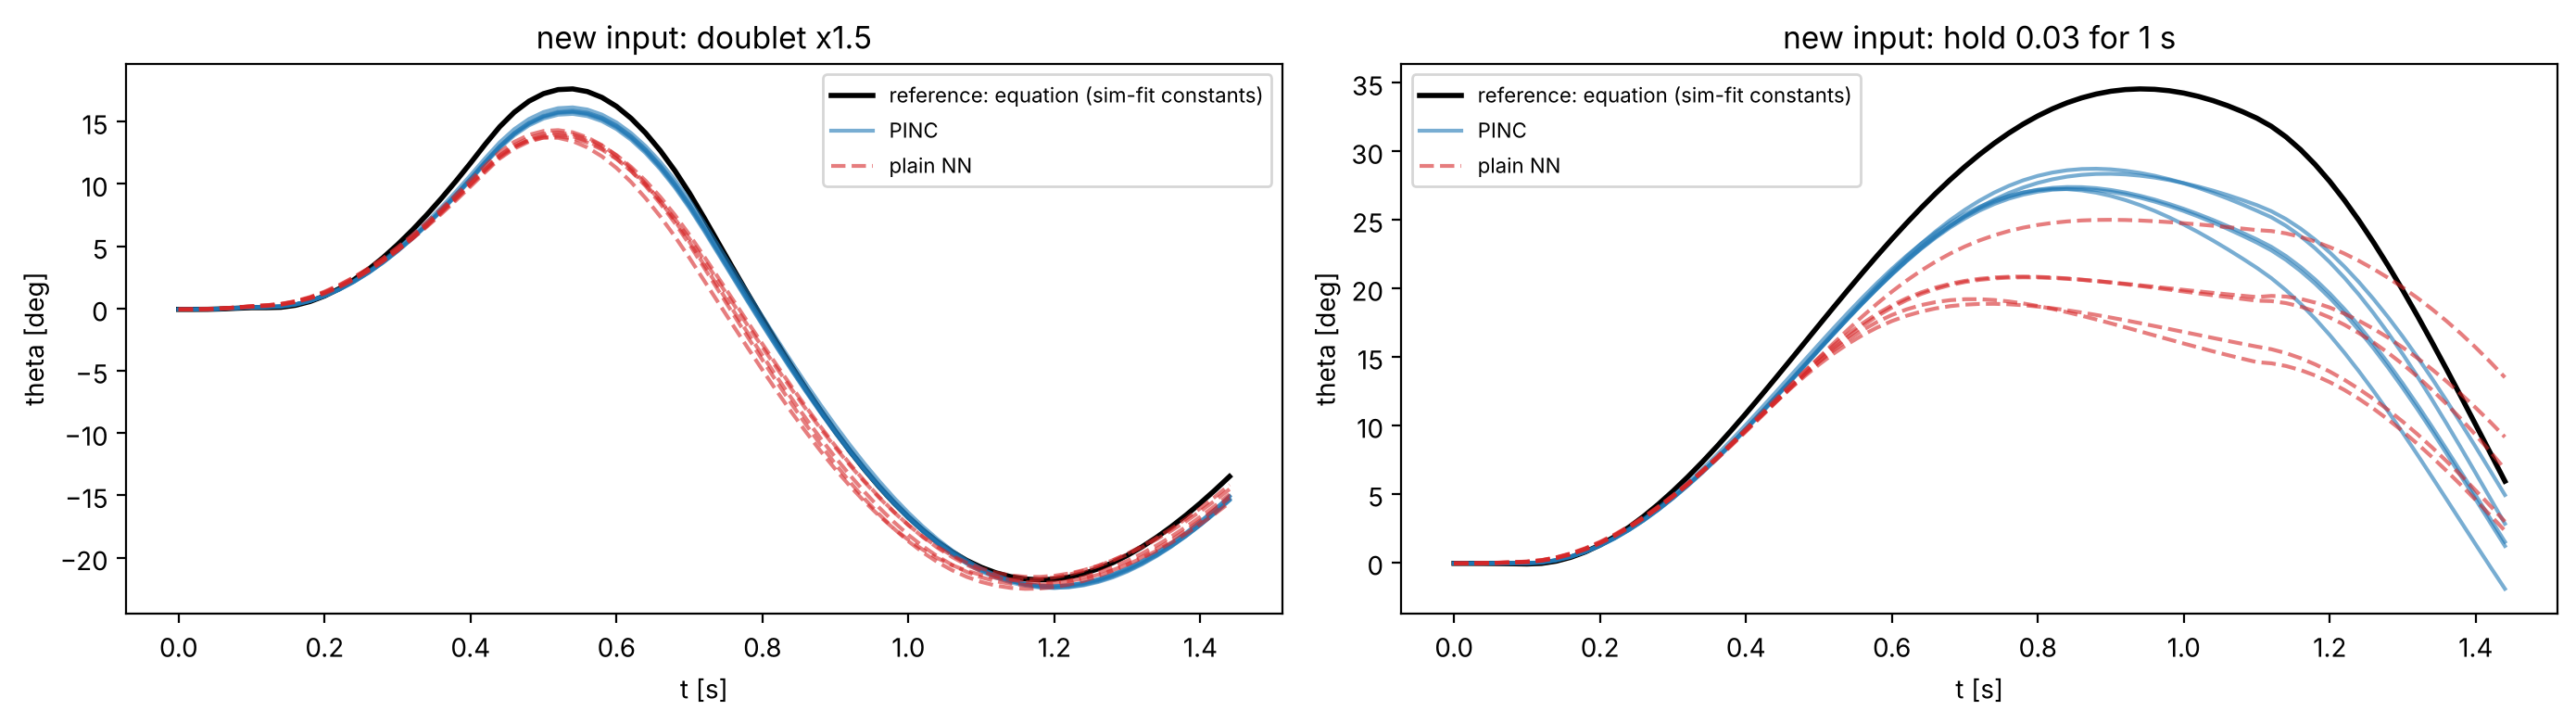

VAF vs reference, mean [%]  VAF std  \
doublet x1.5      PINC                           99.75     0.01   
                  plain NN                       98.67     0.41   
hold 0.03 for 1 s PINC                           93.46     3.08   
                  plain NN                       78.29     6.48   

                            RMSE vs reference [deg]  
doublet x1.5      PINC                         0.95  
                  plain NN                     2.13  
hold 0.03 for 1 s PINC                         4.97  
                  plain NN                     8.40

In [10]:
def new_inputs():
    n = len(M)
    big = M.copy(); big = M[0] + 1.5 * (M - M[0])                           # doublet 1.5x bigger
    hold = np.full(n, M[0]); hold[5:55] = M[0] + 0.03                        # constant push 0.03 for 1 s
    return {'doublet x1.5': big, 'hold 0.03 for 1 s': hold}
rows2 = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (name, Mn) in zip(ax, new_inputs().items()):
    ref = run_open(euler_like_ivp(P_SIM), th[0], q[0], Mn, False)
    a.plot(t, np.degrees(ref), 'k', lw=2, label='reference: equation (sim-fit constants)')
    for label, color, ls in [('PINC', 'C0', '-'), ('plain NN', 'C3', '--')]:
        ys = [run_open(r['step'], th[0], q[0], Mn) for r in runs[label]]
        v = [vaf(ref, y) for y in ys]
        rows2[(name, label)] = [np.mean(v), np.std(v), np.mean([np.degrees(np.sqrt(np.mean((y - ref)**2))) for y in ys])]
        for i, y in enumerate(ys): a.plot(t, np.degrees(y), ls, color=color, alpha=0.6, label=label if i == 0 else None)
    a.set(title='new input: ' + name, xlabel='t [s]', ylabel='theta [deg]'); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('../figures/batch3_new_inputs.png', dpi=120, bbox_inches='tight'); plt.show()
table2 = pd.DataFrame(rows2, index=['VAF vs reference, mean [%]', 'VAF std', 'RMSE vs reference [deg]']).T.round(2)
table2.to_csv('../results/batch3_new_inputs.csv')
table2

## 9. What this shows
- **Measured test flight:** one-step error is tiny for every model; the rollout shows how errors build up over time.
- **New inputs:** the plain NN only learned what it saw; the PINC also learned the equation, so it should stay closer to the reference when the input is new. This is the part that matters for using the model inside a controller.
- The PINC is only as good as the constants in its physics loss (here the inverse-PINN constants, slightly different from the sim fit).